# Machine Learning CA1: NHANES Depression Risk

## Step 1: Import necessary libraries and Load Dataset

In [1067]:
# Import libraries used across the notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

In [1068]:
# Load each NHANES dataset using its CSV filename.
df_DEMO = pd.read_csv("DEMO_L.csv")# Demographic data, including age, sex, and race/ethnicity
df_DPQ = pd.read_csv("DPQ_L.csv")  # Depression screener questionnaire (PHQ-9)
df_MCQ = pd.read_csv("MCQ_L.csv")  # Medical conditions and health history data
df_INQ = pd.read_csv("INQ_L.csv")  # Household income and income-to-poverty ratio data
df_PAQ = pd.read_csv("PAQ_L.csv")  # Physical activity and exercise data
df_SLQ = pd.read_csv("SLQ_L.csv")  # Sleep and sleep habits data
df_ALQ = pd.read_csv("ALQ_L.csv")  # Alcohol use data
df_BMX = pd.read_csv("BMX_L.csv")  # Body measurements, including weight, height, and BMI

## Step 2: Data Exploration

Explore the eight source datasets and review the raw data distributions. Data cleaning, filtering, merging, and target creation are carried out in Step 3.

### 2.1 Demographic (DEMO_L) dataset overall

In [1069]:
# Check the dataset row and column count.
print("Demographic shape:", df_DEMO.shape)

Demographic shape: (11933, 27)


In [1070]:
# Check column data types and non-missing counts.
df_DEMO.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   SDDSRVYR  11933 non-null  float64
 2   RIDSTATR  11933 non-null  float64
 3   RIAGENDR  11933 non-null  float64
 4   RIDAGEYR  11933 non-null  float64
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  float64
 7   RIDRETH3  11933 non-null  float64
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  float64
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  4020 non-null   float64
 21  

In [1071]:
# Count missing values by column.
print("\nMissing values in Demographic:")
print(df_DEMO.isnull().sum())


Missing values in Demographic:
SEQN            0
SDDSRVYR        0
RIDSTATR        0
RIAGENDR        0
RIDAGEYR        0
RIDAGEMN    11556
RIDRETH1        0
RIDRETH3        0
RIDEXMON     3073
RIDEXAGM     9146
DMQMILIZ     3632
DMDBORN4       19
DMDYRUSR    10058
DMDEDUC2     4139
DMDMARTZ     4141
RIDEXPRG    10430
DMDHHSIZ        0
DMDHRGND     7818
DMDHRAGZ     7809
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHSEDZ     9806
WTINT2YR        0
WTMEC2YR        0
SDMVSTRA        0
SDMVPSU         0
INDFMPIR     2041
dtype: int64


In [1072]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Demographic:")
print(df_DEMO.describe())

Descriptive statistics for Demographic:
                SEQN  SDDSRVYR      RIDSTATR      RIAGENDR      RIDAGEYR  \
count   11933.000000   11933.0  11933.000000  11933.000000  1.193300e+04   
mean   136344.000000      12.0      1.742479      1.532808  3.831786e+01   
std      3444.904716       0.0      0.437287      0.498943  2.560199e+01   
min    130378.000000      12.0      1.000000      1.000000  5.397605e-79   
25%    133361.000000      12.0      1.000000      1.000000  1.300000e+01   
50%    136344.000000      12.0      2.000000      2.000000  3.700000e+01   
75%    139327.000000      12.0      2.000000      2.000000  6.200000e+01   
max    142310.000000      12.0      2.000000      2.000000  8.000000e+01   

           RIDAGEMN      RIDRETH1      RIDRETH3     RIDEXMON      RIDEXAGM  \
count  3.770000e+02  11933.000000  11933.000000  8860.000000  2.787000e+03   
mean   1.162865e+01      3.104584      3.320540     1.520203  1.219085e+02   
std    6.805429e+00      1.076346      1.

In [1073]:
# Summarize the age distribution.
print("Age distribution:")
print(df_DEMO["RIDAGEYR"].describe())

Age distribution:
count    1.193300e+04
mean     3.831786e+01
std      2.560199e+01
min      5.397605e-79
25%      1.300000e+01
50%      3.700000e+01
75%      6.200000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64


#### Inspect `INDFMPIR` in the DEMO_L Dataset

Review the raw ratio of family income to poverty before cleaning. A tiny exported value that corresponds to zero in the original NHANES XPT file will be corrected during Step 3.

In [1074]:
df_DEMO["INDFMPIR"].describe()

count    9.892000e+03
mean     2.708174e+00
std      1.670119e+00
min      5.397605e-79
25%      1.180000e+00
50%      2.500000e+00
75%      4.500000e+00
max      5.000000e+00
Name: INDFMPIR, dtype: float64

### 2.2 Depression Screener (DPQ_L) dataset overall

In [1075]:
# Check the dataset row and column count.
print("Depression Screener shape:", df_DPQ.shape)

Depression Screener shape: (6337, 11)


In [1076]:
# Check column data types and non-missing counts.
df_DPQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   DPQ010  5519 non-null   float64
 2   DPQ020  5518 non-null   float64
 3   DPQ030  5516 non-null   float64
 4   DPQ040  5514 non-null   float64
 5   DPQ050  5513 non-null   float64
 6   DPQ060  5510 non-null   float64
 7   DPQ070  5508 non-null   float64
 8   DPQ080  5508 non-null   float64
 9   DPQ090  5506 non-null   float64
 10  DPQ100  4167 non-null   float64
dtypes: float64(11)
memory usage: 544.7 KB


In [1077]:
# Count missing values by column.
print("\nMissing values in Depression Screener:")
print(df_DPQ.isnull().sum())


Missing values in Depression Screener:
SEQN         0
DPQ010     818
DPQ020     819
DPQ030     821
DPQ040     823
DPQ050     824
DPQ060     827
DPQ070     829
DPQ080     829
DPQ090     831
DPQ100    2170
dtype: int64


In [1078]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Depression Screener:")
print(df_DPQ.describe())

Descriptive statistics for Depression Screener:
                SEQN        DPQ010        DPQ020        DPQ030        DPQ040  \
count    6337.000000  5.519000e+03  5.518000e+03  5.516000e+03  5.514000e+03   
mean   136348.738362  5.109621e-01  4.786154e-01  7.935098e-01  8.601741e-01   
std      3439.132476  9.466645e-01  8.387239e-01  1.003693e+00  9.651269e-01   
min    130378.000000  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
25%    133337.000000  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
50%    136397.000000  5.397605e-79  5.397605e-79  5.397605e-79  1.000000e+00   
75%    139310.000000  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
max    142310.000000  9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00   

             DPQ050        DPQ060        DPQ070        DPQ080        DPQ090  \
count  5.513000e+03  5.510000e+03  5.508000e+03  5.508000e+03  5.506000e+03   
mean   5.042627e-01  4.110708e-01  3.948802e-01  2.165940e-01  8.209226e-

In [1079]:
# Review distributions for the nine PHQ-9 items.
print("Distribution of PHQ-9 item responses:")
print(df_DPQ[["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050", "DPQ060", "DPQ070", "DPQ080", "DPQ090"]].describe())

Distribution of PHQ-9 item responses:
             DPQ010        DPQ020        DPQ030        DPQ040        DPQ050  \
count  5.519000e+03  5.518000e+03  5.516000e+03  5.514000e+03  5.513000e+03   
mean   5.109621e-01  4.786154e-01  7.935098e-01  8.601741e-01  5.042627e-01   
std    9.466645e-01  8.387239e-01  1.003693e+00  9.651269e-01  8.605773e-01   
min    5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
25%    5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79  5.397605e-79   
50%    5.397605e-79  5.397605e-79  5.397605e-79  1.000000e+00  5.397605e-79   
75%    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
max    9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00  9.000000e+00   

             DPQ060        DPQ070        DPQ080        DPQ090  
count  5.510000e+03  5.508000e+03  5.508000e+03  5.506000e+03  
mean   4.110708e-01  3.948802e-01  2.165940e-01  8.209226e-02  
std    7.869793e-01  7.675240e-01  6.850770e-01  4.381644e

In [1080]:
# List PHQ-9 item columns and the export value representing zero.
dpq_items = ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050","DPQ060", "DPQ070", "DPQ080", "DPQ090"]
dpq_abnormal_value = 5.3976053469340279e-79

In [1081]:
print("Abnormal-value counts by PHQ-9 item before cleaning:")
for col in dpq_items:
    print(col, (df_DPQ[col] == dpq_abnormal_value).sum())

Abnormal-value counts by PHQ-9 item before cleaning:
DPQ010 3703
DPQ020 3674
DPQ030 2772
DPQ040 2348
DPQ050 3710
DPQ060 3971
DPQ070 4036
DPQ080 4748
DPQ090 5207


In [1082]:
print("Missing responses by PHQ-9 item before cleaning:")
print(df_DPQ[dpq_items].isnull().sum())

Missing responses by PHQ-9 item before cleaning:
DPQ010    818
DPQ020    819
DPQ030    821
DPQ040    823
DPQ050    824
DPQ060    827
DPQ070    829
DPQ080    829
DPQ090    831
dtype: int64


#### PHQ-9 Item Response Counts


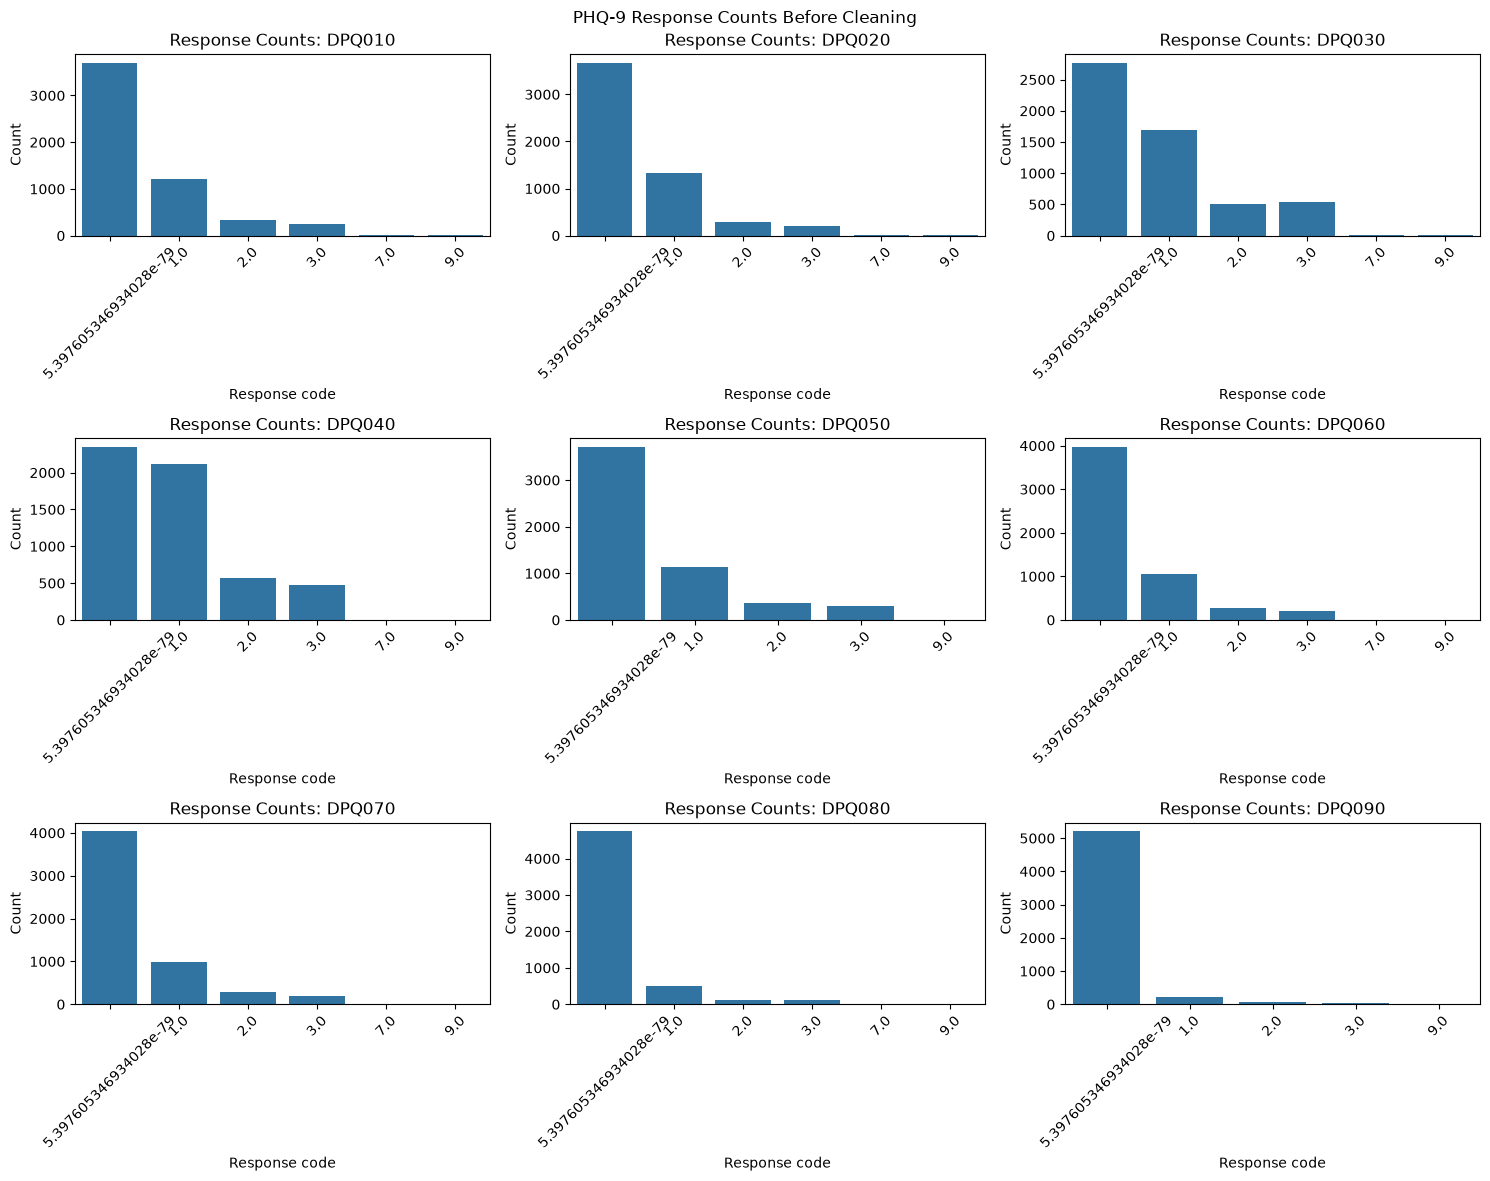

In [1083]:
# Plot raw response-code counts for each PHQ-9 item before cleaning.
dpq_plot_items = dpq_items

plt.close('all')  # Close any existing plots to avoid overlap
fig, axes = plt.subplots(3,3,figsize=(15, 12))

for ax, col in zip(axes.flatten(), dpq_plot_items):
    sns.countplot(x=col, data=df_DPQ, ax=ax)
    ax.set_title(f"Response Counts: {col}")
    ax.set_xlabel("Response code")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=45)

plt.suptitle("PHQ-9 Response Counts Before Cleaning")
plt.tight_layout()
plt.show()


#### Interpretation of the Nine PHQ-9 Item Response Plots

Each plot shows the raw response-code counts for one symptom before cleaning:

- **DPQ010 (little interest or pleasure):** “Not at all” is the most frequent response; responses indicating more frequent symptoms are less common.
- **DPQ020 (feeling down or hopeless):** “Not at all” is most frequent, with progressively fewer reports at the higher symptom-frequency levels.
- **DPQ030 (sleep problems):** “Not at all” remains most frequent, while responses across the symptom-frequency range are visible.
- **DPQ040 (tiredness or low energy):** “Not at all” and “Several days” are comparatively close, making this item less concentrated at code 0 than most of the other items.
- **DPQ050 (appetite change):** “Not at all” is most frequent; higher-frequency symptom responses are less common.
- **DPQ060 (feeling bad about oneself):** “Not at all” clearly dominates the valid response codes.
- **DPQ070 (difficulty concentrating):** “Not at all” clearly dominates; higher-frequency responses occur less often.
- **DPQ080 (moving or speaking slowly, or being unusually restless):** “Not at all” is the most common response and higher-frequency reports are comparatively sparse.
- **DPQ090 (thoughts of self-harm):** “Not at all” is especially dominant; positive frequency responses are relatively rare in these raw counts.

Response codes 7 (refused) and 9 (don't know) are special codes, not symptom-frequency levels, and are treated as missing during cleaning. The tiny value visible in the raw CSV is also handled in the cleaning step. These are full-file raw counts, before the older-adult filter.

### 2.3 Medical Conditions (MCQ_L) dataset overall

In [1084]:
# Check the dataset row and column count.
print("Medical Conditions shape:", df_MCQ.shape)

Medical Conditions shape: (11744, 35)


In [1085]:
# Check column data types and non-missing counts.
df_MCQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 11744 entries, 0 to 11743
Data columns (total 35 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     11744 non-null  float64
 1   MCQ010   11743 non-null  float64
 2   MCQ035   1946 non-null   float64
 3   MCQ040   1219 non-null   float64
 4   MCQ050   1219 non-null   float64
 5   AGQ030   11743 non-null  float64
 6   MCQ053   11741 non-null  float64
 7   MCQ149   434 non-null    float64
 8   MCQ160A  7807 non-null   float64
 9   MCQ195   2532 non-null   float64
 10  MCQ160B  7808 non-null   float64
 11  MCQ160C  7807 non-null   float64
 12  MCQ160D  7808 non-null   float64
 13  MCQ160E  7807 non-null   float64
 14  MCQ160F  7806 non-null   float64
 15  MCQ160M  7806 non-null   float64
 16  MCQ170M  1053 non-null   float64
 17  MCQ160P  7807 non-null   float64
 18  MCQ160L  7807 non-null   float64
 19  MCQ170L  425 non-null    float64
 20  MCQ500   1578 non-null   float64
 21  MCQ510A  260 non-null  

In [1086]:
# Count missing values by column.
print("\nMissing values in Medical Conditions:")
print(df_MCQ.isnull().sum())


Missing values in Medical Conditions:
SEQN           0
MCQ010         1
MCQ035      9798
MCQ040     10525
MCQ050     10525
AGQ030         1
MCQ053         3
MCQ149     11310
MCQ160A     3937
MCQ195      9212
MCQ160B     3936
MCQ160C     3937
MCQ160D     3936
MCQ160E     3937
MCQ160F     3938
MCQ160M     3938
MCQ170M    10691
MCQ160P     3937
MCQ160L     3937
MCQ170L    11319
MCQ500     10166
MCQ510A    11484
MCQ510B    11740
MCQ510C    11697
MCQ510D    11682
MCQ510E    11728
MCQ510F    11665
MCQ550      3937
MCQ560      3937
MCQ220      3937
MCQ230A    10575
MCQ230B    11585
MCQ230C    11718
MCQ230D    11742
OSQ230      6021
dtype: int64


In [1087]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Medical Conditions:")
print(df_MCQ.describe())

Descriptive statistics for Medical Conditions:
                SEQN        MCQ010      MCQ035       MCQ040       MCQ050  \
count   11744.000000  11743.000000  1946.00000  1219.000000  1219.000000   
mean   136347.896373      1.843226     1.50668     1.538146     1.879409   
std      3445.908868      0.451382     1.14690     0.657767     0.445073   
min    130378.000000      1.000000     1.00000     1.000000     1.000000   
25%    133359.750000      2.000000     1.00000     1.000000     2.000000   
50%    136354.500000      2.000000     1.00000     2.000000     2.000000   
75%    139327.250000      2.000000     2.00000     2.000000     2.000000   
max    142310.000000      9.000000     9.00000     9.000000     9.000000   

             AGQ030        MCQ053      MCQ149      MCQ160A       MCQ195  ...  \
count  11743.000000  11741.000000  434.000000  7807.000000  2532.000000  ...   
mean       1.830537      1.967720    1.884793     1.690918     3.093602  ...   
std        0.439566      0.2

### 2.4 Income (INQ_L) dataset overall

In [1088]:
# Check the dataset row and column count.
print("Income shape:", df_INQ.shape)

Income shape: (11933, 5)


In [1089]:
# Check column data types and non-missing counts.
df_INQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   INDFMMPI  8989 non-null   float64
 2   INDFMMPC  10464 non-null  float64
 3   INQ300    10468 non-null  float64
 4   IND310    5650 non-null   float64
dtypes: float64(5)
memory usage: 466.3 KB


In [1090]:
# Count missing values by column.
print("\nMissing values in Income:")
print(df_INQ.isnull().sum())


Missing values in Income:
SEQN           0
INDFMMPI    2944
INDFMMPC    1469
INQ300      1465
IND310      6283
dtype: int64


In [1091]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Income:")
print(df_INQ.describe())

Descriptive statistics for Income:
                SEQN      INDFMMPI      INDFMMPC        INQ300       IND310
count   11933.000000  8.989000e+03  10464.000000  10468.000000  5650.000000
mean   136344.000000  2.529415e+00      2.419438      1.796141     3.606549
std      3444.904716  1.607884e+00      1.315262      1.299623    13.268089
min    130378.000000  5.397605e-79      1.000000      1.000000     1.000000
25%    133361.000000  1.160000e+00      1.000000      1.000000     1.000000
50%    136344.000000  2.160000e+00      3.000000      2.000000     1.000000
75%    139327.000000  4.000000e+00      3.000000      2.000000     2.000000
max    142310.000000  5.000000e+00      9.000000      9.000000    99.000000


### 2.5 Physical Activity (PAQ_L) dataset overall

In [1092]:
# Check the dataset row and column count.
print("Physical Activity shape:", df_PAQ.shape)

Physical Activity shape: (8153, 8)


In [1093]:
# Check column data types and non-missing counts.
df_PAQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 8153 entries, 0 to 8152
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     8153 non-null   float64
 1   PAD790Q  8135 non-null   float64
 2   PAD790U  8153 non-null   str    
 3   PAD800   6390 non-null   float64
 4   PAD810Q  8139 non-null   float64
 5   PAD810U  8153 non-null   str    
 6   PAD820   3687 non-null   float64
 7   PAD680   8138 non-null   float64
dtypes: float64(6), str(2)
memory usage: 509.7 KB


In [1094]:
# Count missing values by column.
print("\nMissing values in Physical Activity:")
print(df_PAQ.isnull().sum())


Missing values in Physical Activity:
SEQN          0
PAD790Q      18
PAD790U       0
PAD800     1763
PAD810Q      14
PAD810U       0
PAD820     4466
PAD680       15
dtype: int64


In [1095]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Physical Activity:")
print(df_PAQ.describe())

Descriptive statistics for Physical Activity:
                SEQN       PAD790Q       PAD800       PAD810Q       PAD820  \
count    8153.000000  8.135000e+03  6390.000000  8.139000e+03  3687.000000   
mean   136378.394579  6.014247e+01    93.437715  4.921084e+01    97.571467   
std      3440.455897  7.417083e+02   544.415142  6.852722e+02   605.421908   
min    130378.000000  5.397605e-79     1.000000  5.397605e-79     1.000000   
25%    133395.000000  1.000000e+00    30.000000  5.397605e-79    30.000000   
50%    136419.000000  2.000000e+00    60.000000  5.397605e-79    45.000000   
75%    139346.000000  4.000000e+00    60.000000  2.000000e+00    60.000000   
max    142310.000000  9.999000e+03  9999.000000  9.999000e+03  9999.000000   

             PAD680  
count  8.138000e+03  
mean   4.469827e+02  
std    9.174642e+02  
min    5.397605e-79  
25%    1.800000e+02  
50%    3.000000e+02  
75%    4.800000e+02  
max    9.999000e+03  


In [1096]:
df_PAQ.describe()

,SEQN,PAD790Q,PAD800,PAD810Q,PAD820,PAD680
count,8153.000000,8.135000e+03,6390.000000,8.139000e+03,3687.000000,8.138000e+03
mean,136378.394579,6.014247e+01,93.437715,4.921084e+01,97.571467,4.469827e+02
std,3440.455897,7.417083e+02,544.415142,6.852722e+02,605.421908,9.174642e+02
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,1.000000,5.397605e-79
25%,133395.000000,1.000000e+00,30.000000,5.397605e-79,30.000000,1.800000e+02
50%,136419.000000,2.000000e+00,60.000000,5.397605e-79,45.000000,3.000000e+02
75%,139346.000000,4.000000e+00,60.000000,2.000000e+00,60.000000,4.800000e+02
max,142310.000000,9.999000e+03,9999.000000,9.999000e+03,9999.000000,9.999000e+03


### 2.6 Sleep Disorders (SLQ_L) dataset overall

In [1097]:
# Check the dataset row and column count.
print("Sleep Disorders shape:", df_SLQ.shape)

Sleep Disorders shape: (8501, 7)


In [1098]:
# Check column data types and non-missing counts.
df_SLQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 8501 entries, 0 to 8500
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    8501 non-null   float64
 1   SLQ300  8501 non-null   str    
 2   SLQ310  8501 non-null   str    
 3   SLD012  8388 non-null   float64
 4   SLQ320  8501 non-null   str    
 5   SLQ330  8501 non-null   str    
 6   SLD013  8387 non-null   float64
dtypes: float64(3), str(4)
memory usage: 465.0 KB


In [1099]:
# Count missing values by column.
print("\nMissing values in Sleep Disorders:")
print(df_SLQ.isnull().sum())


Missing values in Sleep Disorders:
SEQN        0
SLQ300      0
SLQ310      0
SLD012    113
SLQ320      0
SLQ330      0
SLD013    114
dtype: int64


In [1100]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Sleep Disorders:")
print(df_SLQ.describe())

Descriptive statistics for Sleep Disorders:
                SEQN       SLD012       SLD013
count    8501.000000  8388.000000  8387.000000
mean   136369.136572     7.757332     8.353762
std      3443.283289     1.616056     1.730015
min    130378.000000     2.000000     2.000000
25%    133378.000000     7.000000     7.500000
50%    136402.000000     8.000000     8.500000
75%    139342.000000     8.500000     9.000000
max    142310.000000    14.000000    14.000000


### 2.7 Alcohol Use (ALQ_L) dataset overall

In [1101]:
# Check the dataset row and column count.
print("Alcohol Use shape:", df_ALQ.shape)

Alcohol Use shape: (6337, 9)


In [1102]:
# Check column data types and non-missing counts.
df_ALQ.info()

<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   ALQ111  5481 non-null   float64
 2   ALQ121  4922 non-null   float64
 3   ALQ130  4069 non-null   float64
 4   ALQ142  4082 non-null   float64
 5   ALQ270  2366 non-null   float64
 6   ALQ280  2362 non-null   float64
 7   ALQ151  4901 non-null   float64
 8   ALQ170  2358 non-null   float64
dtypes: float64(9)
memory usage: 445.7 KB


In [1103]:
# Count missing values by column.
print("\nMissing values in Alcohol Use:")
print(df_ALQ.isnull().sum())


Missing values in Alcohol Use:
SEQN         0
ALQ111     856
ALQ121    1415
ALQ130    2268
ALQ142    2255
ALQ270    3971
ALQ280    3975
ALQ151    1436
ALQ170    3979
dtype: int64


In [1104]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Alcohol Use:")
print(df_ALQ.describe())

Descriptive statistics for Alcohol Use:
                SEQN       ALQ111        ALQ121       ALQ130        ALQ142  \
count    6337.000000  5481.000000  4.922000e+03  4069.000000  4.082000e+03   
mean   136348.738362     1.109104  5.030679e+00     5.842959  4.742283e+00   
std      3439.132476     0.385114  4.314321e+00    54.996448  7.326042e+00   
min    130378.000000     1.000000  5.397605e-79     1.000000  5.397605e-79   
25%    133337.000000     1.000000  2.000000e+00     1.000000  5.397605e-79   
50%    136397.000000     1.000000  5.000000e+00     2.000000  4.000000e+00   
75%    139310.000000     1.000000  8.000000e+00     3.000000  9.000000e+00   
max    142310.000000     9.000000  9.900000e+01   999.000000  9.900000e+01   

             ALQ270        ALQ280       ALQ151        ALQ170  
count  2.366000e+03  2.362000e+03  4901.000000  2.358000e+03  
mean   4.838123e+00  3.545301e+00     1.821261  4.396098e+00  
std    7.785415e+00  7.133496e+00     0.458352  4.525245e+01  
min  

### 2.8 Body Measures (BMX_L) dataset overall

In [1105]:
# Check the dataset row and column count.
print("Body Measures shape:", df_BMX.shape)

Body Measures shape: (8860, 22)


In [1106]:
# Check column data types and non-missing counts.
df_BMX.info()

<class 'pandas.DataFrame'>
RangeIndex: 8860 entries, 0 to 8859
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      8860 non-null   float64
 1   BMDSTATS  8860 non-null   float64
 2   BMXWT     8754 non-null   float64
 3   BMIWT     345 non-null    float64
 4   BMXRECUM  454 non-null    float64
 5   BMIRECUM  18 non-null     float64
 6   BMXHEAD   70 non-null     float64
 7   BMIHEAD   0 non-null      float64
 8   BMXHT     8499 non-null   float64
 9   BMIHT     134 non-null    float64
 10  BMXBMI    8471 non-null   float64
 11  BMDBMIC   2492 non-null   float64
 12  BMXLEG    7335 non-null   float64
 13  BMILEG    396 non-null    float64
 14  BMXARML   8568 non-null   float64
 15  BMIARML   200 non-null    float64
 16  BMXARMC   8562 non-null   float64
 17  BMIARMC   205 non-null    float64
 18  BMXWAIST  8190 non-null   float64
 19  BMIWAIST  347 non-null    float64
 20  BMXHIP    6776 non-null   float64
 21  BM

In [1107]:
# Count missing values by column.
print("\nMissing values in Body Measures:")
print(df_BMX.isnull().sum())


Missing values in Body Measures:
SEQN           0
BMDSTATS       0
BMXWT        106
BMIWT       8515
BMXRECUM    8406
BMIRECUM    8842
BMXHEAD     8790
BMIHEAD     8860
BMXHT        361
BMIHT       8726
BMXBMI       389
BMDBMIC     6368
BMXLEG      1525
BMILEG      8464
BMXARML      292
BMIARML     8660
BMXARMC      298
BMIARMC     8655
BMXWAIST     670
BMIWAIST    8513
BMXHIP      2084
BMIHIP      8499
dtype: int64


In [1108]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics for Body Measures:")
print(df_BMX.describe())

Descriptive statistics for Body Measures:
                SEQN     BMDSTATS        BMXWT       BMIWT    BMXRECUM  \
count    8860.000000  8860.000000  8754.000000  345.000000  454.000000   
mean   136345.828217     1.132280    70.549037    2.881159   84.329956   
std      3453.776310     0.503848    30.389021    0.624424   14.058157   
min    130378.000000     1.000000     2.700000    1.000000   48.500000   
25%    133319.750000     1.000000    54.200000    3.000000   73.475000   
50%    136377.500000     1.000000    71.700000    3.000000   84.700000   
75%    139336.250000     1.000000    89.100000    3.000000   96.100000   
max    142310.000000     4.000000   248.200000    4.000000  118.800000   

       BMIRECUM    BMXHEAD  BMIHEAD        BMXHT       BMIHT  ...  \
count      18.0  70.000000      0.0  8499.000000  134.000000  ...   
mean        1.0  41.932857      NaN   159.664549    2.313433  ...   
std         0.0   2.798484      NaN    19.864943    0.953174  ...   
min         1.0

## Step 3: Data Preparation

Correct known export/special response values, select older adults, clean PHQ-9 responses, merge the NHANES components, and create the project target.

### 3.1 Clean Special Values in Selected Predictors

`INDFMPIR` is part of `DEMO_L`. The tiny CSV value was compared with the original NHANES XPT data and confirmed to represent 0; this is an export correction, not missing-value imputation. So this dataset to missing for later training-mean imputation ([NHANES DEMO_L codebook](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm))

In [1109]:
# Correct the tiny CSV export value that was confirmed as zero in the original XPT data.
income_export_zero = 5.3976053469340279e-79
df_DEMO["INDFMPIR"] = df_DEMO["INDFMPIR"].replace(income_export_zero, 0)

In [1110]:
# Summarize the INDFMPIR ratio of family income to poverty distribution.
print("Family income distribution:")
print(df_DEMO["INDFMPIR"].describe())

Family income distribution:
count    9892.000000
mean        2.708174
std         1.670119
min         0.000000
25%         1.180000
50%         2.500000
75%         4.500000
max         5.000000
Name: INDFMPIR, dtype: float64


In [1111]:
df_DEMO["INDFMPIR"].isnull().sum()

np.int64(2041)

#### Clean `PAD680` Refused and Unknown Responses
`PAD680` is part of `PAQ_L`; its official codebook identifies 7777 as Refused and 9999 as Don't know, so this dataset to missing for later training-mean imputation ([NHANES PAQ_L codebook](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm)).

In [1112]:
# Convert the NHANES refused and don't-know codes to missing values.
df_PAQ["PAD680"] = df_PAQ["PAD680"].replace({7777: np.nan, 9999: np.nan})

### 3.2 Filter Older Adults

#### Age distribution

Filter Older Adults

Keep participants aged 60 years and older, as required for this analysis.

In [1113]:
# Keep participants aged 60 years and older.
df_older_adults = df_DEMO.loc[df_DEMO["RIDAGEYR"] >= 60].copy()

print("Participants aged 60 or older:", df_older_adults.shape[0])

Participants aged 60 or older: 3504


#### Older Adults Age Distribution Histogram

This histogram shows the age distribution of participants retained by the age filter

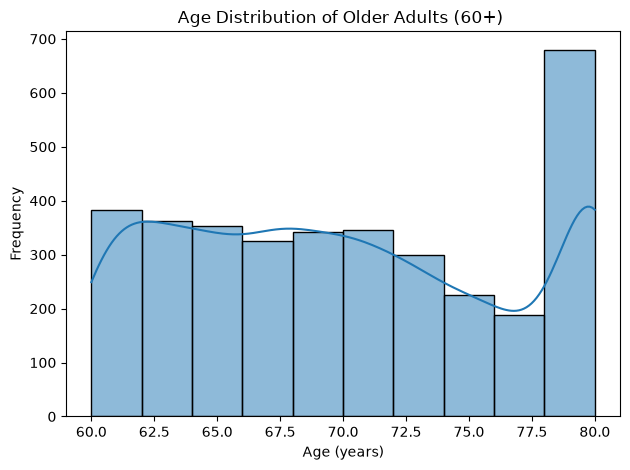

In [1114]:
# Plot the age distribution for participants aged 60 or older.

sns.histplot(df_older_adults, x="RIDAGEYR", binwidth = 2, kde = True)  # Bins from 60 to 80 years
plt.title("Age Distribution of Older Adults (60+) ")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Interpretation of the Older-Adult Age Histogram

The filtered sample contains 3,504 participants with recorded ages from 60 to 80. Ages 60–79 are spread across the range, while the bar at 80 is notably taller. NHANES top-codes ages 80 and older as 80, so that bar includes participants aged 80 or above rather than only people exactly 80 years old ([official NHANES DEMO_L codebook](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm)).

### 3.3 Clean PHQ-9 Responses

For DPQ010–DPQ090, treat NHANES refusal code 7 and unknown code 9 as missing. Correct the tiny CSV export value to 0 based on comparison with the original XPT data. Participants must have nine valid responses before `PHQ9_Total` is calculated.

In [1115]:
# Correct the export value and treat refused or unknown answers as missing.
df_DPQ[dpq_items] = df_DPQ[dpq_items].replace(dpq_abnormal_value, 0)
df_DPQ[dpq_items] = df_DPQ[dpq_items].replace({7: np.nan, 9: np.nan})

In [1116]:
print("Missing responses by PHQ-9 item after cleaning:")
print(df_DPQ[dpq_items].isnull().sum())

Missing responses by PHQ-9 item after cleaning:
DPQ010    839
DPQ020    829
DPQ030    828
DPQ040    831
DPQ050    827
DPQ060    832
DPQ070    832
DPQ080    841
DPQ090    836
dtype: int64


The increase in missing values ​​is a result of converting "Refused" and "Don't know" responses into missing values, while abnormal values ​​have been replaced with 0, as previously specified.

## Step 4: Merge Data and Quality Checks

### Merge Datasets Using SEQN

Merge the seven NHANES component files onto the older-adult demographic records. A left merge keeps all participants aged 60 or older and leaves missing values where a component record is unavailable.

In [1117]:
# Merge each NHANES component by participant ID (SEQN).
#df_older_adults of course is the same as df_DEMO[df_DEMO["RIDAGEYR"] >= 60]
df_NHANES_60plus = df_older_adults.merge(df_DPQ, on="SEQN", how="left") # Merge the depression screener(df_DPQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_MCQ, on="SEQN", how="left") # Merge the medical conditions (df_MCQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_INQ, on="SEQN", how="left") # Merge the income questionnaire (df_INQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_PAQ, on="SEQN", how="left") # Merge the physical activity questionnaire (df_PAQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_SLQ, on="SEQN", how="left") # Merge the sleep questionnaire (df_SLQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_ALQ, on="SEQN", how="left") # Merge the alcohol questionnaire (df_ALQ) data with the older adults demographic data
df_NHANES_60plus = df_NHANES_60plus.merge(df_BMX, on="SEQN", how="left") # Merge the body measurements (df_BMX) data with the older adults demographic data

df_NHANES_merged = df_NHANES_60plus.copy()
print("Merged older-adult dataset shape:", df_NHANES_merged.shape)

Merged older-adult dataset shape: (3504, 117)


In [1457]:
# Check merge counts
print("Older adults rows before merging:", df_older_adults.shape[0])
print("Rows after merging:", df_NHANES_merged.shape[0])

Older adults rows before merging: 3504
Rows after merging: 3504


In [1458]:
# Check Missing SEQN
print("Missing SEQN after merging:", df_NHANES_merged["SEQN"].isnull().sum())

Missing SEQN after merging: 0


In [1459]:
# Check Duplicate SEQN 
print("Duplicate SEQN after merging:", df_NHANES_merged["SEQN"].duplicated().sum())

Duplicate SEQN after merging: 0


### 3.5 Inspect Missing Values

In [1460]:
# Show all selected features
selected_features = [
    "RIDAGEYR", "INDFMPIR","DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050","DPQ060", "DPQ070", "DPQ080", "DPQ090",
    "BMXBMI", "SLD012", "SLD013", "PAD680","RIAGENDR", "RIDRETH3","MCQ010", "MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D", 
    "MCQ160E","MCQ160F", "MCQ160L", "MCQ160M", "MCQ160P", "MCQ220", "MCQ550"]

In [1461]:
print(df_NHANES_merged[selected_features].info())

<class 'pandas.DataFrame'>
RangeIndex: 3504 entries, 0 to 3503
Data columns (total 29 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   RIDAGEYR  3504 non-null   float64
 1   INDFMPIR  2902 non-null   float64
 2   DPQ010    2422 non-null   float64
 3   DPQ020    2431 non-null   float64
 4   DPQ030    2432 non-null   float64
 5   DPQ040    2428 non-null   float64
 6   DPQ050    2430 non-null   float64
 7   DPQ060    2426 non-null   float64
 8   DPQ070    2429 non-null   float64
 9   DPQ080    2423 non-null   float64
 10  DPQ090    2425 non-null   float64
 11  BMXBMI    2722 non-null   float64
 12  SLD012    3441 non-null   float64
 13  SLD013    3443 non-null   float64
 14  PAD680    3457 non-null   float64
 15  RIAGENDR  3504 non-null   float64
 16  RIDRETH3  3504 non-null   float64
 17  MCQ010    3504 non-null   float64
 18  MCQ160A   3504 non-null   float64
 19  MCQ160B   3504 non-null   float64
 20  MCQ160C   3503 non-null   float64
 21  MC

In [1462]:
# Count missing values by column.
print("\nMissing values in Merge NHANES:")
print(df_NHANES_merged[selected_features].isnull().sum())


Missing values in Merge NHANES:
RIDAGEYR       0
INDFMPIR     602
DPQ010      1082
DPQ020      1073
DPQ030      1072
DPQ040      1076
DPQ050      1074
DPQ060      1078
DPQ070      1075
DPQ080      1081
DPQ090      1079
BMXBMI       782
SLD012        63
SLD013        61
PAD680        47
RIAGENDR       0
RIDRETH3       0
MCQ010         0
MCQ160A        0
MCQ160B        0
MCQ160C        1
MCQ160D        0
MCQ160E        0
MCQ160F        1
MCQ160L        1
MCQ160M        1
MCQ160P        1
MCQ220         1
MCQ550         1
dtype: int64


In [1463]:
print(df_NHANES_merged[selected_features].describe())

          RIDAGEYR     INDFMPIR       DPQ010       DPQ020       DPQ030  \
count  3504.000000  2902.000000  2422.000000  2431.000000  2432.000000   
mean     69.936073     2.965524     0.412056     0.353764     0.725740   
std       6.526428     1.609807     0.790476     0.705581     0.959498   
min      60.000000     0.000000     0.000000     0.000000     0.000000   
25%      64.000000     1.510000     0.000000     0.000000     0.000000   
50%      69.000000     2.870000     0.000000     0.000000     0.000000   
75%      75.000000     4.920000     1.000000     0.500000     1.000000   
max      80.000000     5.000000     3.000000     3.000000     3.000000   

            DPQ040       DPQ050       DPQ060       DPQ070       DPQ080  ...  \
count  2428.000000  2430.000000  2426.000000  2429.000000  2423.000000  ...   
mean      0.752471     0.414403     0.258862     0.276657     0.167974  ...   
std       0.914164     0.781553     0.612392     0.650081     0.544712  ...   
min       0.00000

### 3.6 PHQ9_Total(DPQ10-90) and Define the Target

Keep participants with complete responses across all nine items of the PHQ-9 questionnaire (total score ranging from 0 to 27) were retained to compute the composite score (`PHQ9_Total`). Subsequently, a target variable `Depression_Risk` was constructed, assigned a value of 1 if `PHQ9_Total >= 10`  and 0 otherwise.
This threshold of 10 follows established clinical standards for screening moderate-to-severe depression, demonstrating a validated sensitivity and specificity of 88% ([Kroenke et al., 2001](https://pmc.ncbi.nlm.nih.gov/articles/PMC1495268/)). Notably, this classification serves strictly as a preliminary statistical screening indicator rather than a formal medical diagnosis.

In [1597]:
# Keep records of PHQ-9 questionnaire responses that include all 9 items
df_NHANES_60plus["PHQ9_Answered"] = df_NHANES_60plus[dpq_items].notna().sum(axis=1)
df_NHANES_60plus = df_NHANES_60plus.loc[df_NHANES_60plus["PHQ9_Answered"] == 9].copy() #Responses that include all 9 items
print("Completed PHQ-9 assessment records for 60plus:", df_NHANES_60plus.shape[0])

Completed PHQ-9 assessment records for 60plus: 2394


In [1774]:
# Total score ranging from 0 to 27
print("PHQ9_Total:", df_NHANES_60plus["PHQ9_Total"].min(), "to", df_NHANES_60plus["PHQ9_Total"].max())

PHQ9_Total: 0.0 to 26.0


In [1917]:
# Define the PHQ9 target
df_NHANES_60plus["Depression_Risk"] = (df_NHANES_60plus["PHQ9_Total"] >= 10).astype(int)
print(df_NHANES_60plus["Depression_Risk"].value_counts())

Depression_Risk
0    2171
1     223
Name: count, dtype: int64


In [1918]:
# Remaining missing values
print("Missing Depression_Risk values:", df_NHANES_60plus["Depression_Risk"].isnull().sum())

Missing Depression_Risk values: 0


#### Depression Risk Class Distribution

In [1919]:
# Count participants by age and depression risk.
age_risk_table = pd.crosstab(df_NHANES_60plus["RIDAGEYR"], df_NHANES_60plus["Depression_Risk"])
age_risk_table["Total"] = age_risk_table.sum(axis=1)
print(age_risk_table)

Depression_Risk    0   1  Total
RIDAGEYR                       
60.0             124  19    143
61.0             126  17    143
62.0             135  12    147
63.0             121  15    136
64.0             117   8    125
65.0             128  13    141
66.0              99  10    109
67.0             120  10    130
68.0             123  22    145
69.0             100  11    111
70.0             116  14    130
71.0             103  10    113
72.0              94   4     98
73.0              96   6    102
74.0              61  10     71
75.0              73   8     81
76.0              62   6     68
77.0              55   2     57
78.0              40   4     44
79.0              51   4     55
80.0             227  18    245


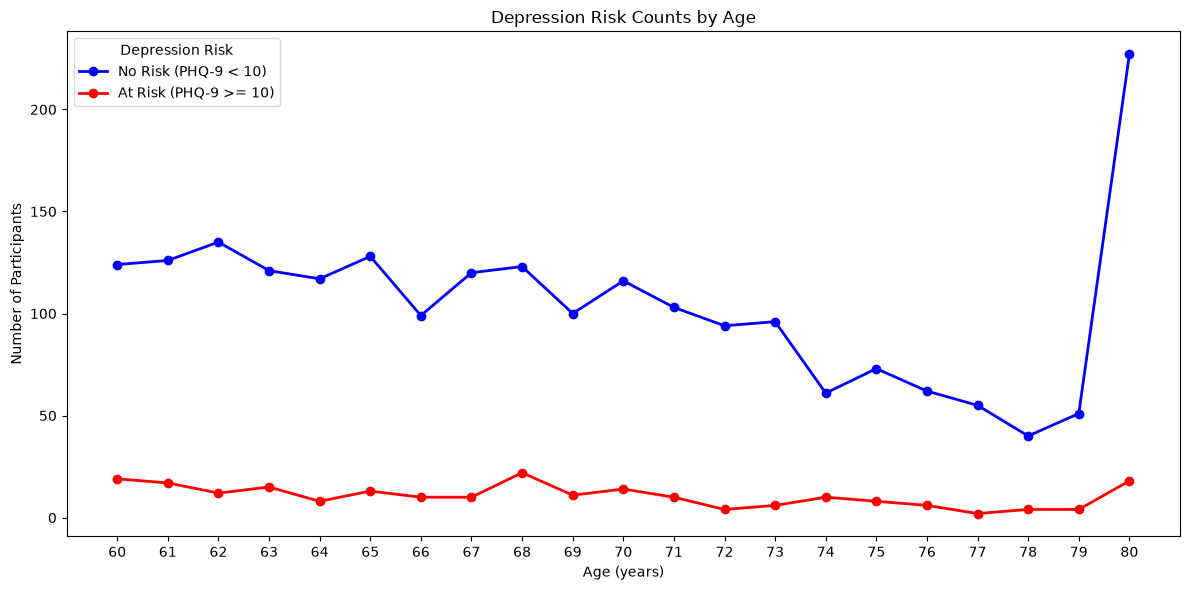

In [1920]:
# Line plot: Depression Risk counts by age.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(age_risk_table.index,age_risk_table[0],marker="o",color="blue",linewidth=2,label="No Risk (PHQ-9 < 10)")
ax.plot(age_risk_table.index,age_risk_table[1],marker="o",color="red",linewidth=2,label="At Risk (PHQ-9 >= 10)")
ax.set_xlim(59, 81)
ax.set_xticks(range(60,81,1))
ax.legend(title="Depression Risk")

plt.title("Depression Risk Counts by Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Participants")
plt.tight_layout()
plt.show()


#### Interpretation of the Depression-Risk Class Count Plot

Across ages 60 to 80, participants in the No Risk `PHQ-9 < 10` group consistently outnumber those in the At Risk `PHQ-9 >= 10` group, highlighting a clear class imbalance. While No Risk counts gradually decline from age 60 to 78 before spiking sharply at age 80 (likely due to age top-coding for individuals aged 80+), the At Risk group remains relatively stable at low levels (under 25 cases per age) throughout the observed range.

### 3.7 Handle Missing Values and Select feature

In [1975]:
# Select feature
continuous_features_data = ["RIDAGEYR", "INDFMPIR", "BMXBMI", "SLD012", "SLD013", "PAD680"]
mcq_condition_columns = ["MCQ010", "MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E","MCQ160F", "MCQ160L", "MCQ160M", "MCQ160P", "MCQ220", "MCQ550"]
categorical_features_data= ["RIAGENDR", "RIDRETH3"] + mcq_condition_columns

features_data = continuous_features_data + categorical_features_data

print(features_data)

['RIDAGEYR', 'INDFMPIR', 'BMXBMI', 'SLD012', 'SLD013', 'PAD680', 'RIAGENDR', 'RIDRETH3', 'MCQ010', 'MCQ160A', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ160L', 'MCQ160M', 'MCQ160P', 'MCQ220', 'MCQ550']


In [1976]:
# Prepare and encode the selected feature columns before defining X.
features_cols = df_NHANES_60plus[features_data].copy()

## Step 5: Define X and y

Use age, income-to-poverty ratio, BMI, weekday and weekend sleep duration, sedentary activity time, sex (`RIAGENDR`), race/ethnicity (`RIDRETH3`), and 12 reported-condition fields from MCQ as candidate predictors. The MCQ predictors represent whether a health professional ever reported the condition; Yes, No, and unknown/refused/missing are kept as separate categories. Encode the categorical predictors with `LabelEncoder`, as shown in the instructor's classification comparison tutorial.

Exclude `SEQN`, PHQ-9 items, `PHQ9_Total`, and `Depression_Risk` from `X`. Continuous-feature missing values are filled with the training-set means after each split. The unknown/refused/missing responses in categorical predictors are retained as their own encoded category.

In [1977]:
# split dataset in features and target variable

X = df_NHANES_60plus[feature_cols].copy() # Features of the dataset

# Represent MCQ answers as reported yes, reported no, or unknown/refused/missing.
for col in mcq_condition_columns:
    X[col] = X[col].map({1: "Reported diagnosis", 2: "No reported diagnosis"})
    X[col] = X[col].fillna("Unknown / refused / missing")

# Encode categorical predictors with LabelEncoder, following the instructor's tutorial.
for col in ["RIAGENDR", "RIDRETH3"]:
    X[col] = X[col].fillna("Unknown / missing").astype(str)

label_encoders = {}
for col in categorical_feature_cols:
    label_encoders[col] = LabelEncoder()
    X[col] = label_encoders[col].fit_transform(X[col].astype(str))

y = df_NHANES_60plus["Depression_Risk"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2394, 20)
y shape: (2394,)


In [1978]:
print("Missing values in selected features:")
missing_feature_values = X.isnull().sum()
print(missing_feature_values[missing_feature_values > 0].sort_values(ascending=False))
print("\nEncoded category labels:")
for col, encoder in label_encoders.items():
    print(col, dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

Missing values in selected features:
INDFMPIR    288
SLD012       35
SLD013       31
BMXBMI       23
PAD680       16
dtype: int64

Encoded category labels:
RIAGENDR {'1.0': np.int64(0), '2.0': np.int64(1)}
RIDRETH3 {'1.0': np.int64(0), '2.0': np.int64(1), '3.0': np.int64(2), '4.0': np.int64(3), '6.0': np.int64(4), '7.0': np.int64(5)}
MCQ010 {'No reported diagnosis': np.int64(0), 'Reported diagnosis': np.int64(1), 'Unknown / refused / missing': np.int64(2)}
MCQ160A {'No reported diagnosis': np.int64(0), 'Reported diagnosis': np.int64(1), 'Unknown / refused / missing': np.int64(2)}
MCQ160B {'No reported diagnosis': np.int64(0), 'Reported diagnosis': np.int64(1), 'Unknown / refused / missing': np.int64(2)}
MCQ160C {'No reported diagnosis': np.int64(0), 'Reported diagnosis': np.int64(1), 'Unknown / refused / missing': np.int64(2)}
MCQ160D {'No reported diagnosis': np.int64(0), 'Reported diagnosis': np.int64(1), 'Unknown / refused / missing': np.int64(2)}
MCQ160E {'No reported diagnosis': n

## Step 6: Train-Test Split

Create separate 5%, 15%, and 25% test splits using the `train_test_split` method shown in Tutorial 3 and `random_state=42` as used in the instructor comparison tutorial. For each split, calculate feature means from its training data and use those same means to fill missing values in the training and test sets.

In [1979]:
# Create each requested split and fill feature missing values from its training mean.
# 5% test set
X_train_05, X_test_05, y_train_05, y_test_05 = train_test_split(X, y, test_size=0.05, random_state=42)
X_train_mean_05 = X_train_05.mean()
X_train_05 = X_train_05.fillna(X_train_mean_05)
X_test_05 = X_test_05.fillna(X_train_mean_05)

print("5% split:", X_train_05.shape, X_test_05.shape)
print("Remaining missing values in 5% training set:", X_train_05.isnull().sum().sum())
print("Remaining missing values in 5% test set:", X_test_05.isnull().sum().sum())

5% split: (2274, 20) (120, 20)
Remaining missing values in 5% training set: 0
Remaining missing values in 5% test set: 0


In [1980]:
# 15% test set
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(
    X, y, test_size=0.15, random_state=42)
X_train_mean_15 = X_train_15.mean()
X_train_15 = X_train_15.fillna(X_train_mean_15)
X_test_15 = X_test_15.fillna(X_train_mean_15)

print("15% split:", X_train_15.shape, X_test_15.shape)
print("Remaining missing values in 15% training set:", X_train_15.isnull().sum().sum())
print("Remaining missing values in 15% test set:", X_test_15.isnull().sum().sum())

15% split: (2034, 20) (360, 20)
Remaining missing values in 15% training set: 0
Remaining missing values in 15% test set: 0


In [1981]:
# 25% test set
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X, y, test_size=0.25, random_state=42)
X_train_mean_25 = X_train_25.mean()
X_train_25 = X_train_25.fillna(X_train_mean_25)
X_test_25 = X_test_25.fillna(X_train_mean_25)

print("25% split:", X_train_25.shape, X_test_25.shape)
print("Remaining missing values in 25% training set:", X_train_25.isnull().sum().sum())
print("Remaining missing values in 25% test set:", X_test_25.isnull().sum().sum())

25% split: (1795, 20) (599, 20)
Remaining missing values in 25% training set: 0
Remaining missing values in 25% test set: 0


### 6.1 Check Class Distribution Before SMOTE and Model Training

Compare the number and percentage of Class 0 and Class 1 observations in each training and test set. This confirms the original imbalance before SMOTE and records the test-set distribution that must remain unchanged.

In [1982]:
# Summarize class counts and percentages before SMOTE for every requested split.
class_distribution_before_smote = {}
class_distribution_rows = []

split_targets = {
    "5%": (y_train_05, y_test_05),
    "15%": (y_train_15, y_test_15),
    "25%": (y_train_25, y_test_25)
}

for split_name, (y_train_split, y_test_split) in split_targets.items():
    class_distribution_before_smote[split_name] = {}

    for dataset_name, target_values in [("Training Set", y_train_split), ("Test Set", y_test_split)]:
        class_counts = target_values.value_counts().reindex([0, 1], fill_value=0)
        class_distribution_before_smote[split_name][dataset_name] = class_counts.copy()
        class_percentages = (class_counts / len(target_values) * 100).round(2)

        class_distribution_rows.append({
            "Test Split": split_name,
            "Dataset": dataset_name,
            "Class 0 Count": class_counts[0],
            "Class 0 (%)": class_percentages[0],
            "Class 1 Count": class_counts[1],
            "Class 1 (%)": class_percentages[1],
            "Total": len(target_values)
        })

class_distribution_before_smote_df = pd.DataFrame(class_distribution_rows)
display(class_distribution_before_smote_df)
print("Class 1 is the Depression_Risk group; these are the original counts before SMOTE.")

,Test Split,Dataset,Class 0 Count,Class 0 (%),Class 1 Count,Class 1 (%),Total
0,5%,Training Set,2059,90.55,215,9.45,2274
1,5%,Test Set,112,93.33,8,6.67,120
2,15%,Training Set,1844,90.66,190,9.34,2034
3,15%,Test Set,327,90.83,33,9.17,360
4,25%,Training Set,1627,90.64,168,9.36,1795
5,25%,Test Set,544,90.82,55,9.18,599


Class 1 is the Depression_Risk group; these are the original counts before SMOTE.


## Step 7: Build ML Models

Fit Logistic Regression and Random Forest with `random_state=42` on each training split. Scale features for Logistic Regression as shown in Tutorial 5; fit Random Forest on the original split features. Generate test-set predictions for both models.

### 7.1 Logistic Regression and Random Forest with 5% Test Set


In [1983]:
# Fit Logistic Regression for the 5% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_05 = StandardScaler()
X_train_scaled_05 = sc_05.fit_transform(X_train_05)
X_test_scaled_05 = sc_05.transform(X_test_05)

log_model_05 = LogisticRegression(max_iter=1000, random_state=42)
log_model_05.fit(X_train_scaled_05, y_train_05)
log_pred_05 = log_model_05.predict(X_test_scaled_05)

# Fit Random Forest for the same split.
rf_model_05 = RandomForestClassifier(n_estimators=1000, random_state=42)
rf_model_05.fit(X_train_05, y_train_05)
rf_pred_05 = rf_model_05.predict(X_test_05)

print("Both models fitted for the 5% test split.")

Both models fitted for the 5% test split.


### 7.2 Logistic Regression and Random Forest with 15% Test Set


In [1984]:
# Fit Logistic Regression for the 15% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_15 = StandardScaler()
X_train_scaled_15 = sc_15.fit_transform(X_train_15)
X_test_scaled_15 = sc_15.transform(X_test_15)

log_model_15 = LogisticRegression(max_iter=1000, random_state=42)
log_model_15.fit(X_train_scaled_15, y_train_15)
log_pred_15 = log_model_15.predict(X_test_scaled_15)

# Fit Random Forest for the same split.
rf_model_15 = RandomForestClassifier(n_estimators=1000, random_state=42)
rf_model_15.fit(X_train_15, y_train_15)
rf_pred_15 = rf_model_15.predict(X_test_15)

print("Both models fitted for the 15% test split.")

Both models fitted for the 15% test split.


### 7.3 Logistic Regression and Random Forest with 25% Test Set


In [1985]:
# Fit Logistic Regression for the 25% test split.
# Scale the split features for Logistic Regression, following Tutorial 5.
sc_25 = StandardScaler()
X_train_scaled_25 = sc_25.fit_transform(X_train_25)
X_test_scaled_25 = sc_25.transform(X_test_25)

log_model_25 = LogisticRegression(max_iter=1000, random_state=42)
log_model_25.fit(X_train_scaled_25, y_train_25)
log_pred_25 = log_model_25.predict(X_test_scaled_25)

# Fit Random Forest for the same split.
rf_model_25 = RandomForestClassifier(n_estimators=1000, random_state=42)
rf_model_25.fit(X_train_25, y_train_25)
rf_pred_25 = rf_model_25.predict(X_test_25)

print("Both models fitted for the 25% test split.")

Both models fitted for the 25% test split.


## Step 8: Cross-validation

Use five-fold cross-validation on each training split to compare model accuracy. With `cv=5`, scikit-learn uses stratified folds for binary classifiers by default ([official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)). Logistic Regression uses the scaled training features; Random Forest uses the unscaled features.

### 8.1 Five-fold CV on 5% Test Split

In [1986]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_05 = cross_val_score(estimator=log_model_05, X=X_train_scaled_05, y=y_train_05, scoring="accuracy", cv=5)
cv_rf_05 = cross_val_score(estimator=rf_model_05, X=X_train_05, y=y_train_05, scoring="accuracy", cv=5)

print("5% split - Logistic Regression CV scores:", cv_lr_05)
print("5% split - Logistic Regression mean accuracy:", cv_lr_05.mean())
print("5% split - Random Forest CV scores:", cv_rf_05)
print("5% split - Random Forest mean accuracy:", cv_rf_05.mean())

5% split - Logistic Regression CV scores: [0.89450549 0.90549451 0.9032967  0.90549451 0.90528634]
5% split - Logistic Regression mean accuracy: 0.9028155104807087
5% split - Random Forest CV scores: [0.9032967  0.9032967  0.9010989  0.9032967  0.90528634]
5% split - Random Forest mean accuracy: 0.9032550709202691


### 8.3 Five-fold CV on 15% Test Split

In [1987]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_15 = cross_val_score(estimator=log_model_15, X=X_train_scaled_15, y=y_train_15, scoring="accuracy", cv=5)
cv_rf_15 = cross_val_score(estimator=rf_model_15, X=X_train_15, y=y_train_15, scoring="accuracy", cv=5)

print("15% split - Logistic Regression CV scores:", cv_lr_15)
print("15% split - Logistic Regression mean accuracy:", cv_lr_15.mean())
print("15% split - Random Forest CV scores:", cv_rf_15)
print("15% split - Random Forest mean accuracy:", cv_rf_15.mean())

15% split - Logistic Regression CV scores: [0.8968059  0.91400491 0.9041769  0.90663391 0.9137931 ]
15% split - Logistic Regression mean accuracy: 0.9070829450139796
15% split - Random Forest CV scores: [0.9041769  0.9041769  0.9017199  0.9017199  0.90640394]
15% split - Random Forest mean accuracy: 0.9036395105360622


### 8.5 Five-fold CV on 25% Test Split

In [1988]:
# Calculate five-fold cross-validation accuracy for both models.
cv_lr_25 = cross_val_score(estimator=log_model_25, X=X_train_scaled_25, y=y_train_25, scoring="accuracy", cv=5)
cv_rf_25 = cross_val_score(estimator=rf_model_25, X=X_train_25, y=y_train_25, scoring="accuracy", cv=5)

print("25% split - Logistic Regression CV scores:", cv_lr_25)
print("25% split - Logistic Regression mean accuracy:", cv_lr_25.mean())
print("25% split - Random Forest CV scores:", cv_rf_25)
print("25% split - Random Forest mean accuracy:", cv_rf_25.mean())

25% split - Logistic Regression CV scores: [0.90807799 0.91086351 0.90807799 0.90529248 0.90529248]
25% split - Logistic Regression mean accuracy: 0.9075208913649024
25% split - Random Forest CV scores: [0.90807799 0.90529248 0.90250696 0.90529248 0.90529248]
25% split - Random Forest mean accuracy: 0.9052924791086351


## Step 9: Model Evaluation

Evaluate each model on its held-out test set using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix. The classification report shows Precision, Recall, and F1-score for each class.

### 9.1 Evaluation on 5% Test Set

In [1989]:
# Evaluate Logistic Regression on the 5% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_05, log_pred_05))
print("Logistic Regression classification report:")
print(classification_report(y_test_05, log_pred_05, zero_division=0))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_05, log_pred_05))

Logistic Regression accuracy: 0.9333333333333333
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       112
           1       0.00      0.00      0.00         8

    accuracy                           0.93       120
   macro avg       0.47      0.50      0.48       120
weighted avg       0.87      0.93      0.90       120

Logistic Regression confusion matrix:
[[112   0]
 [  8   0]]


In [1990]:
# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_05, rf_pred_05))
print("Random Forest classification report:")
print(classification_report(y_test_05, rf_pred_05, zero_division=0))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_05, rf_pred_05))

Random Forest accuracy: 0.9333333333333333
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       112
           1       0.00      0.00      0.00         8

    accuracy                           0.93       120
   macro avg       0.47      0.50      0.48       120
weighted avg       0.87      0.93      0.90       120

Random Forest confusion matrix:
[[112   0]
 [  8   0]]


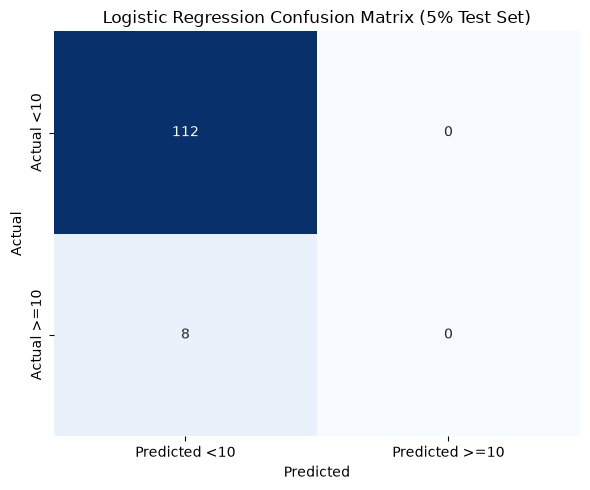

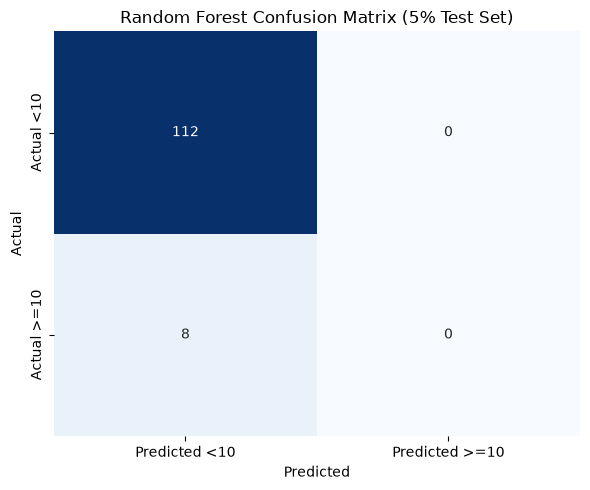

In [1991]:
# Plot Logistic Regression confusion matrix for the 5% test set.
cm_lr_05 = confusion_matrix(y_test_05, log_pred_05, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_05, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (5% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_05 = confusion_matrix(y_test_05, rf_pred_05, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_05, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (5% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#### Interpretation of the Confusion Matrices (5% Test Set)

Both models classify all 112 below-cutoff participants correctly, but also classify all 8 at-risk participants as below the cutoff. There are no false positive predictions, but all actual risk cases are missed. Thus, the 93.3% Accuracy is misleading if the main objective is detecting the risk group; risk-class Recall and F1-score are both 0% for both models.

### 9.3 Evaluation on 15% Test Set

Logistic Regression accuracy: 0.9
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       327
           1       0.00      0.00      0.00        33

    accuracy                           0.90       360
   macro avg       0.45      0.50      0.47       360
weighted avg       0.82      0.90      0.86       360

Logistic Regression confusion matrix:
[[324   3]
 [ 33   0]]
Random Forest accuracy: 0.9111111111111111
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       327
           1       1.00      0.03      0.06        33

    accuracy                           0.91       360
   macro avg       0.96      0.52      0.51       360
weighted avg       0.92      0.91      0.87       360

Random Forest confusion matrix:
[[327   0]
 [ 32   1]]


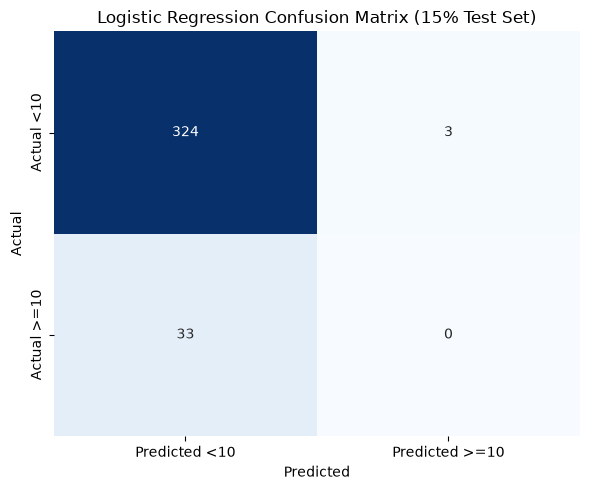

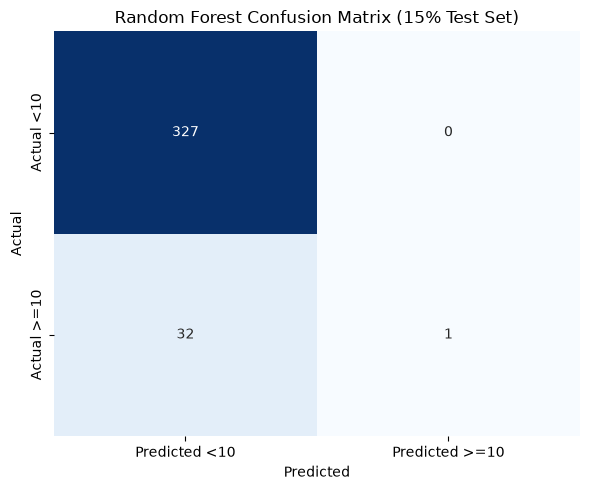

In [1992]:
# Evaluate Logistic Regression on the 15% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_15, log_pred_15))
print("Logistic Regression classification report:")
print(classification_report(y_test_15, log_pred_15))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_15, log_pred_15))

# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_15, rf_pred_15))
print("Random Forest classification report:")
print(classification_report(y_test_15, rf_pred_15))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_15, rf_pred_15))

# Plot Logistic Regression confusion matrix for the 15% test set.
cm_lr_15 = confusion_matrix(y_test_15, log_pred_15, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_15, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (15% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_15 = confusion_matrix(y_test_15, rf_pred_15, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_15, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (15% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#### Interpretation of the Confusion Matrices (15% Test Set)

Logistic Regression correctly classifies 324 participants below the cutoff, flags 3 as at risk when they are below it, and misses all 33 at-risk participants. Random Forest correctly classifies all 327 below-cutoff participants and detects 1 of 33 at-risk participants, missing the other 32. The high Accuracy for both models is driven by the larger below-cutoff group, while risk-class Recall remains 0% for Logistic Regression and about 3% for Random Forest.

### 9.5 Evaluation on 25% Test Set

Logistic Regression accuracy: 0.8981636060100167
Logistic Regression classification report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       544
           1       0.00      0.00      0.00        55

    accuracy                           0.90       599
   macro avg       0.45      0.49      0.47       599
weighted avg       0.82      0.90      0.86       599

Logistic Regression confusion matrix:
[[538   6]
 [ 55   0]]
Random Forest accuracy: 0.9065108514190318
Random Forest classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       544
           1       0.00      0.00      0.00        55

    accuracy                           0.91       599
   macro avg       0.45      0.50      0.48       599
weighted avg       0.82      0.91      0.86       599

Random Forest confusion matrix:
[[543   1]
 [ 55   0]]


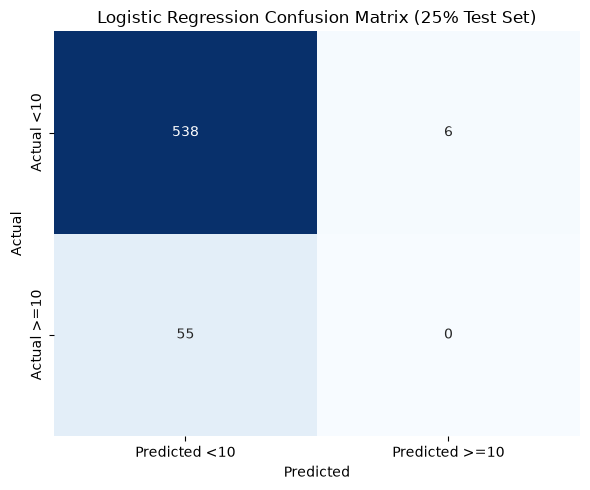

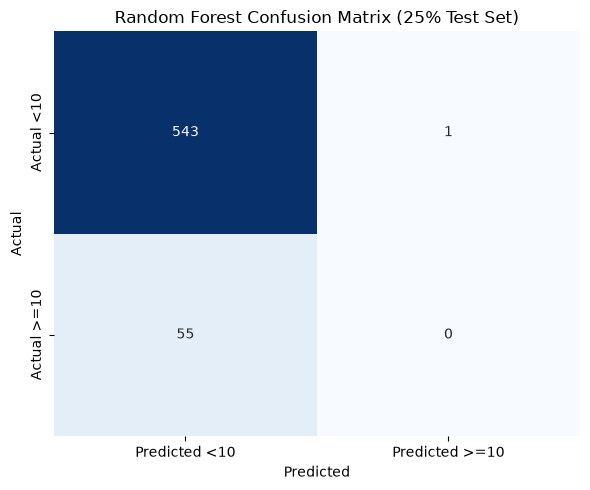

In [1993]:
# Evaluate Logistic Regression on the 25% test set.
print("Logistic Regression accuracy:", metrics.accuracy_score(y_test_25, log_pred_25))
print("Logistic Regression classification report:")
print(classification_report(y_test_25, log_pred_25))
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test_25, log_pred_25))

# Evaluate Random Forest on the same test set.
print("Random Forest accuracy:", metrics.accuracy_score(y_test_25, rf_pred_25))
print("Random Forest classification report:")
print(classification_report(y_test_25, rf_pred_25))
print("Random Forest confusion matrix:")
print(confusion_matrix(y_test_25, rf_pred_25))

# Plot Logistic Regression confusion matrix for the 25% test set.
cm_lr_25 = confusion_matrix(y_test_25, log_pred_25, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr_25, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Logistic Regression Confusion Matrix (25% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Plot Random Forest confusion matrix for the same test set.
cm_rf_25 = confusion_matrix(y_test_25, rf_pred_25, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf_25, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted <10", "Predicted >=10"],
            yticklabels=["Actual <10", "Actual >=10"])
plt.title("Random Forest Confusion Matrix (25% Test Set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#### Interpretation of the Confusion Matrices (25% Test Set)

Both models miss all 55 participants who meet the risk cutoff. Logistic Regression correctly classifies 538 participants below the cutoff and incorrectly flags 6 as at risk. Random Forest correctly classifies 543 below the cutoff and incorrectly flags 1. Their Accuracy is close to 90%, mainly because most test participants are below the cutoff; the matrices show that this Accuracy does not mean either baseline model detects the risk group.

## Step 10: Hyperparameter Tuning with GridSearchCV and Model Comparison

Compare the original training-data baseline with models tuned by GridSearchCV after applying SMOTE to each training split. The held-out test data remain unchanged. GridSearchCV uses five-fold Recall for `Depression_Risk = 1`; all random operations use `random_state=42`.

### 10.1 Apply SMOTE to the Training Data

Keep the original-data models as a baseline. First balance only each training split with the instructor's `SMOTE(random_state=42)` example, then run GridSearchCV for Logistic Regression and Random Forest. Test observations are not resampled.

In [1994]:
# Prepare the three test splits and record the original-model baseline results.
split_data = {
    "5%": {"X_train": X_train_05, "X_test": X_test_05, "X_train_scaled": X_train_scaled_05, "X_test_scaled": X_test_scaled_05, "y_train": y_train_05, "y_test": y_test_05},
    "15%": {"X_train": X_train_15, "X_test": X_test_15, "X_train_scaled": X_train_scaled_15, "X_test_scaled": X_test_scaled_15, "y_train": y_train_15, "y_test": y_test_15},
    "25%": {"X_train": X_train_25, "X_test": X_test_25, "X_train_scaled": X_train_scaled_25, "X_test_scaled": X_test_scaled_25, "y_train": y_train_25, "y_test": y_test_25}
}

baseline_predictions = {
    ("5%", "Logistic Regression"): log_pred_05, ("5%", "Random Forest"): rf_pred_05,
    ("15%", "Logistic Regression"): log_pred_15, ("15%", "Random Forest"): rf_pred_15,
    ("25%", "Logistic Regression"): log_pred_25, ("25%", "Random Forest"): rf_pred_25
}
baseline_cv_accuracy = {
    ("5%", "Logistic Regression"): cv_lr_05.mean(), ("5%", "Random Forest"): cv_rf_05.mean(),
    ("15%", "Logistic Regression"): cv_lr_15.mean(), ("15%", "Random Forest"): cv_rf_15.mean(),
    ("25%", "Logistic Regression"): cv_lr_25.mean(), ("25%", "Random Forest"): cv_rf_25.mean()
}

# Use parameter ranges shown in the instructor's model-comparison tutorial.
param_grids = {
    "Logistic Regression": {"C": [0.1, 0.5, 1, 10]},
    "Random Forest": {"n_estimators": [50, 100, 200], "max_depth": [None, 5, 10, 20, 30]}
}

baseline_results = []
for split_name, split_values in split_data.items():
    for model_name in ["Logistic Regression", "Random Forest"]:
        baseline_pred = baseline_predictions[(split_name, model_name)]
        baseline_report = classification_report(split_values["y_test"], baseline_pred, output_dict=True, zero_division=0)
        baseline_risk = baseline_report.get("1", {})
        baseline_results.append({
            "Test Split": split_name,
            "Training Approach": "Original training data",
            "Model": model_name,
            "Best Parameters": "Default model",
            "Five-fold CV Accuracy": baseline_cv_accuracy[(split_name, model_name)],
            "GridSearch CV Recall": np.nan,
            "Test Accuracy": metrics.accuracy_score(split_values["y_test"], baseline_pred),
            "Risk Precision": baseline_risk.get("precision", 0),
            "Risk Recall": baseline_risk.get("recall", 0),
            "Risk F1-score": baseline_risk.get("f1-score", 0)
        })

baseline_results_df = pd.DataFrame(baseline_results)
print("Original training-data baseline results:")
display(baseline_results_df)

Original training-data baseline results:


,Test Split,Training Approach,Model,Best Parameters,Five-fold CV Accuracy,GridSearch CV Recall,Test Accuracy,Risk Precision,Risk Recall,Risk F1-score
0,5%,Original training data,Logistic Regression,Default model,0.902816,NaN,0.933333,0.0,0.000000,0.000000
1,5%,Original training data,Random Forest,Default model,0.903255,NaN,0.933333,0.0,0.000000,0.000000
2,15%,Original training data,Logistic Regression,Default model,0.907083,NaN,0.900000,0.0,0.000000,0.000000
3,15%,Original training data,Random Forest,Default model,0.903640,NaN,0.911111,1.0,0.030303,0.058824
4,25%,Original training data,Logistic Regression,Default model,0.907521,NaN,0.898164,0.0,0.000000,0.000000
5,25%,Original training data,Random Forest,Default model,0.905292,NaN,0.906511,0.0,0.000000,0.000000


#### Balance Each Training Split with SMOTE

Apply SMOTE separately to the 5%, 15%, and 25% training sets. This leaves each test set unchanged. The predictors include label-encoded categorical values, so standard SMOTE can create intermediate numeric values for those encoded categories; interpret the results with this limitation in mind.

In [1995]:
# Balance each training split with SMOTE and check class counts before and after.
smote_training_data = {}

for split_name, split_values in split_data.items():
    print("\n", split_name, "test split")
    print("Training classes before SMOTE:")
    print(split_values["y_train"].value_counts().sort_index())

    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(
        split_values["X_train"],
        split_values["y_train"]
    )

    smote_training_data[split_name] = {
        "X_train": X_train_smote,
        "y_train": y_train_smote
    }
    print("Training classes after SMOTE:")
    print(y_train_smote.value_counts().sort_index())


 5% test split
Training classes before SMOTE:
Depression_Risk
0    2059
1     215
Name: count, dtype: int64
Training classes after SMOTE:
Depression_Risk
0    2059
1    2059
Name: count, dtype: int64

 15% test split
Training classes before SMOTE:
Depression_Risk
0    1844
1     190
Name: count, dtype: int64
Training classes after SMOTE:
Depression_Risk
0    1844
1    1844
Name: count, dtype: int64

 25% test split
Training classes before SMOTE:
Depression_Risk
0    1627
1     168
Name: count, dtype: int64
Training classes after SMOTE:
Depression_Risk
0    1627
1    1627
Name: count, dtype: int64


#### Checkpoint Before Hyperparameter Tuning

Confirm that SMOTE balanced only the training targets, each test set retains its original class counts and sample size, and the following Logistic Regression tuning cell fits `StandardScaler` on training data before transforming the test data.

In [1996]:
# Verify the resampled training sets are balanced and each test set is unchanged.
smote_checkpoint_rows = []

for split_name, split_values in split_data.items():
    train_before = class_distribution_before_smote[split_name]["Training Set"]
    test_before = class_distribution_before_smote[split_name]["Test Set"]
    train_after = smote_training_data[split_name]["y_train"].value_counts().reindex([0, 1], fill_value=0)
    test_current = split_values["y_test"].value_counts().reindex([0, 1], fill_value=0)

    assert len(smote_training_data[split_name]["X_train"]) == len(smote_training_data[split_name]["y_train"])
    assert train_after[0] == train_after[1]
    assert test_current.equals(test_before)
    assert len(split_values["X_test"]) == int(test_before.sum())

    for dataset_name, counts in [("Training before SMOTE", train_before),
                                 ("Training after SMOTE", train_after),
                                 ("Test set (unchanged)", test_current)]:
        percentages = (counts / counts.sum() * 100).round(2)
        smote_checkpoint_rows.append({
            "Test Split": split_name,
            "Dataset Status": dataset_name,
            "Class 0 Count": counts[0],
            "Class 0 (%)": percentages[0],
            "Class 1 Count": counts[1],
            "Class 1 (%)": percentages[1],
            "Total": int(counts.sum())
        })

smote_checkpoint_df = pd.DataFrame(smote_checkpoint_rows)
display(smote_checkpoint_df)
print("Checkpoint passed: SMOTE balanced training targets only; test counts and sizes are unchanged.")
print("Scaling checkpoint: the GridSearchCV cell fits StandardScaler on training features and only transforms test features.")

,Test Split,Dataset Status,Class 0 Count,Class 0 (%),Class 1 Count,Class 1 (%),Total
0,5%,Training before SMOTE,2059,90.55,215,9.45,2274
1,5%,Training after SMOTE,2059,50.00,2059,50.00,4118
2,5%,Test set (unchanged),112,93.33,8,6.67,120
3,15%,Training before SMOTE,1844,90.66,190,9.34,2034
4,15%,Training after SMOTE,1844,50.00,1844,50.00,3688
5,15%,Test set (unchanged),327,90.83,33,9.17,360
6,25%,Training before SMOTE,1627,90.64,168,9.36,1795
7,25%,Training after SMOTE,1627,50.00,1627,50.00,3254
8,25%,Test set (unchanged),544,90.82,55,9.18,599


Checkpoint passed: SMOTE balanced training targets only; test counts and sizes are unchanged.
Scaling checkpoint: the GridSearchCV cell fits StandardScaler on training features and only transforms test features.


### 10.2 Hyperparameter Tuning with GridSearchCV

Run GridSearchCV separately for Logistic Regression and Random Forest on each SMOTE-balanced training split. Logistic Regression uses the same StandardScaler workflow as before. Five-fold CV and the held-out evaluation use `Depression_Risk = 1` Recall as the tuning metric.

In [1997]:
# Tune and evaluate both models using the SMOTE-balanced training splits.
smote_gridsearch_models = {}
smote_gridsearch_predictions = {}
smote_gridsearch_scalers = {}
smote_gridsearch_results = []

for split_name, split_values in split_data.items():
    smote_values = smote_training_data[split_name]

    for model_name in ["Logistic Regression", "Random Forest"]:
        if model_name == "Logistic Regression":
            estimator = LogisticRegression(max_iter=1000, random_state=42)
            scaler = StandardScaler()
            # Fit scaling on SMOTE-balanced training data only; transform the untouched test data.
            X_train_search = scaler.fit_transform(smote_values["X_train"])
            X_test_search = scaler.transform(split_values["X_test"])
            smote_gridsearch_scalers[(split_name, model_name)] = scaler
        else:
            estimator = RandomForestClassifier(random_state=42)
            X_train_search = smote_values["X_train"]
            X_test_search = split_values["X_test"]

        grid_search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grids[model_name],
            cv=5,
            scoring="recall",
            n_jobs=-1
        )
        grid_search.fit(X_train_search, smote_values["y_train"])

        best_model = grid_search.best_estimator_
        y_pred_grid = best_model.predict(X_test_search)
        report = classification_report(
            split_values["y_test"], y_pred_grid,
            output_dict=True, zero_division=0
        )
        risk_metrics = report.get("1", {})

        smote_gridsearch_models[(split_name, model_name)] = best_model
        smote_gridsearch_predictions[(split_name, model_name)] = y_pred_grid
        smote_gridsearch_results.append({
            "Test Split": split_name,
            "Training Approach": "SMOTE + GridSearchCV",
            "Model": model_name,
            "Best Parameters": grid_search.best_params_,
            "Five-fold CV Accuracy": np.nan,
            "GridSearch CV Recall": grid_search.best_score_,
            "Test Accuracy": metrics.accuracy_score(split_values["y_test"], y_pred_grid),
            "Risk Precision": risk_metrics.get("precision", 0),
            "Risk Recall": risk_metrics.get("recall", 0),
            "Risk F1-score": risk_metrics.get("f1-score", 0)
        })

smote_gridsearch_results_df = pd.DataFrame(smote_gridsearch_results)
print("SMOTE + GridSearchCV results:")
display(smote_gridsearch_results_df)

SMOTE + GridSearchCV results:


,Test Split,Training Approach,Model,Best Parameters,Five-fold CV Accuracy,GridSearch CV Recall,Test Accuracy,Risk Precision,Risk Recall,Risk F1-score
0,5%,SMOTE + GridSearchCV,Logistic Regression,{'C': 1},NaN,0.741652,0.633333,0.071429,0.375000,0.120000
1,5%,SMOTE + GridSearchCV,Random Forest,"{'max_depth': 20, 'n_estimators': 200}",NaN,0.908730,0.833333,0.000000,0.000000,0.000000
2,15%,SMOTE + GridSearchCV,Logistic Regression,{'C': 0.1},NaN,0.734307,0.641667,0.093220,0.333333,0.145695
3,15%,SMOTE + GridSearchCV,Random Forest,"{'max_depth': 20, 'n_estimators': 100}",NaN,0.926280,0.808333,0.026316,0.030303,0.028169
4,25%,SMOTE + GridSearchCV,Logistic Regression,{'C': 0.1},NaN,0.725831,0.641068,0.091837,0.327273,0.143426
5,25%,SMOTE + GridSearchCV,Random Forest,"{'max_depth': 20, 'n_estimators': 200}",NaN,0.917578,0.836394,0.078431,0.072727,0.075472


### 10.3 Compare Baseline and Tuned Model Results

Combine original-data baseline results, SMOTE + GridSearchCV results.

In [1998]:
# Combine original-data baseline results with SMOTE + GridSearchCV results.
tuning_results_df = pd.concat(
    [baseline_results_df, smote_gridsearch_results_df],
    ignore_index=True
)
print("Baseline and SMOTE + GridSearchCV results:")
display(tuning_results_df)

Baseline and SMOTE + GridSearchCV results:


,Test Split,Training Approach,Model,Best Parameters,Five-fold CV Accuracy,GridSearch CV Recall,Test Accuracy,Risk Precision,Risk Recall,Risk F1-score
0,5%,Original training data,Logistic Regression,Default model,0.902816,NaN,0.933333,0.000000,0.000000,0.000000
1,5%,Original training data,Random Forest,Default model,0.903255,NaN,0.933333,0.000000,0.000000,0.000000
2,15%,Original training data,Logistic Regression,Default model,0.907083,NaN,0.900000,0.000000,0.000000,0.000000
3,15%,Original training data,Random Forest,Default model,0.903640,NaN,0.911111,1.000000,0.030303,0.058824
4,25%,Original training data,Logistic Regression,Default model,0.907521,NaN,0.898164,0.000000,0.000000,0.000000
5,25%,Original training data,Random Forest,Default model,0.905292,NaN,0.906511,0.000000,0.000000,0.000000
6,5%,SMOTE + GridSearchCV,Logistic Regression,{'C': 1},NaN,0.741652,0.633333,0.071429,0.375000,0.120000
7,5%,SMOTE + GridSearchCV,Random Forest,"{'max_depth': 20, 'n_estimators': 200}",NaN,0.908730,0.833333,0.000000,0.000000,0.000000
8,15%,SMOTE + GridSearchCV,Logistic Regression,{'C': 0.1},NaN,0.734307,0.641667,0.093220,0.333333,0.145695
9,15%,SMOTE + GridSearchCV,Random Forest,"{'max_depth': 20, 'n_estimators': 100}",NaN,0.926280,0.808333,0.026316,0.030303,0.028169


### 10.4 Compare Recall and F1 Across Test Splits

Compare risk-class Recall and F1 across 5%, 15%, and 25% test sets for the original baseline, SMOTE + GridSearchCV.

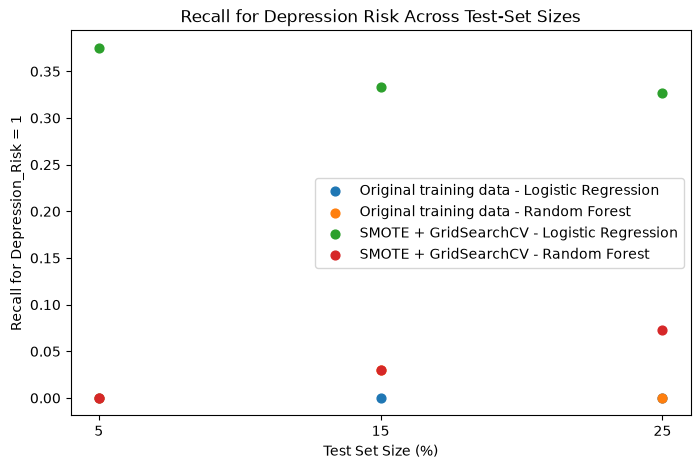

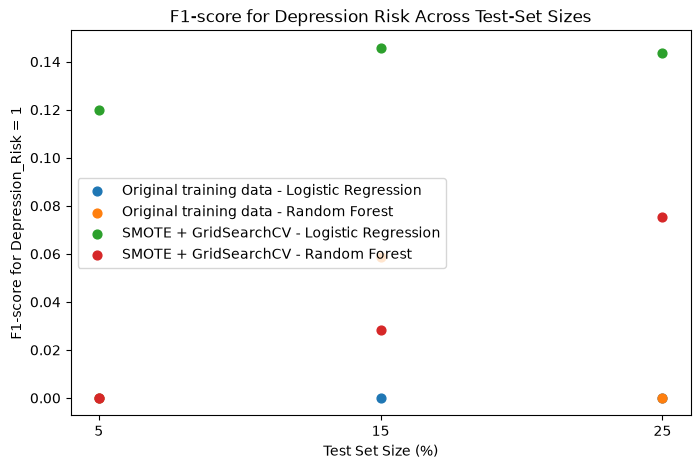

In [1999]:
# Compare risk-class Recall and F1 across the requested test-set sizes.
test_split_order = ["5%", "15%", "25%"]
test_split_values = [5, 15, 25]
model_names = ["Logistic Regression", "Random Forest"]
approach_names = ["Original training data", "SMOTE + GridSearchCV"]

for metric_column, metric_name in [("Risk Recall", "Recall"), ("Risk F1-score", "F1-score")]:
    plt.figure(figsize=(8, 5))

    for approach_name in approach_names:
        for model_name in model_names:
            chart_data = tuning_results_df.loc[
                (tuning_results_df["Training Approach"] == approach_name)
                & (tuning_results_df["Model"] == model_name)
            ].set_index("Test Split").loc[test_split_order]

            plt.scatter(
                test_split_values,
                chart_data[metric_column],
                s=40,
                label=approach_name + " - " + model_name
            )

    plt.title(metric_name + " for Depression Risk Across Test-Set Sizes")
    plt.xlabel("Test Set Size (%)")
    plt.ylabel(metric_name + " for Depression_Risk = 1")
    plt.xticks(test_split_values)
    plt.legend()
    plt.show()

#### Interpretation of the Recall and F1-score Plots

**Recall plot:** SMOTE + GridSearchCV Logistic Regression has the highest risk-class Recall at all three test sizes: 37.5% (5%), 33.3% (15%), and 32.7% (25%). The corresponding Random Forest Recall is 0%, 3.0%, and 7.3%. The original Logistic Regression has 0% Recall throughout; original Random Forest reaches 3.0% only at 15%.

**F1-score plot:** Logistic Regression with SMOTE + GridSearchCV also has the highest risk-class F1 at each split: 0.120, 0.146, and 0.143. Random Forest reaches 0.000, 0.028, and 0.075. This indicates that, in this run, resampling plus tuning helped Logistic Regression detect more risk cases, while its low Precision means many of those positive predictions are false positives.

### 10.5 Feature Importance for RQ1

Use the SMOTE + GridSearchCV-selected Random Forest fitted on the 25% training split to rank the selected predictors with `feature_importances_`, following the Random Forest practical. Importance scores describe predictive contribution in this fitted model; they do not show that a factor causes depression risk.

In [2000]:
# Rank predictors by importance from the selected SMOTE + GridSearchCV Random Forest.
rf_model_25_tuned = smote_gridsearch_models[("25%", "Random Forest")]
feature_importance = pd.Series(
    rf_model_25_tuned.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("SMOTE + GridSearchCV Random Forest feature importance (25% test split):")
print(feature_importance)

SMOTE + GridSearchCV Random Forest feature importance (25% test split):
INDFMPIR    0.209918
SLD012      0.136713
SLD013      0.131264
BMXBMI      0.105532
RIDAGEYR    0.099176
PAD680      0.089047
RIDRETH3    0.038802
MCQ220      0.033654
RIAGENDR    0.027411
MCQ160A     0.018436
MCQ160C     0.015962
MCQ550      0.015948
MCQ160M     0.014900
MCQ010      0.013434
MCQ160E     0.010527
MCQ160P     0.010130
MCQ160L     0.009166
MCQ160B     0.007847
MCQ160F     0.007579
MCQ160D     0.004554
dtype: float64


### 10.6 Select and Evaluate the Final Tuned Model

Compare the SMOTE + GridSearchCV-selected Logistic Regression and Random Forest on the unchanged 25% held-out test set. Select by F1-score for `Depression_Risk = 1`, then Recall, with Accuracy as a tie-breaker.

Selected final model: Logistic Regression
Best parameters: {'C': 0.1}
GridSearchCV five-fold Recall: 0.7258310523831996
Selection order: risk-class F1, then Recall, then Accuracy as a tie-breaker
Held-out test accuracy: 0.6410684474123539
Precision for Depression_Risk = 1: 0.09183673469387756
Recall for Depression_Risk = 1: 0.32727272727272727
F1-score for Depression_Risk = 1: 0.14342629482071714


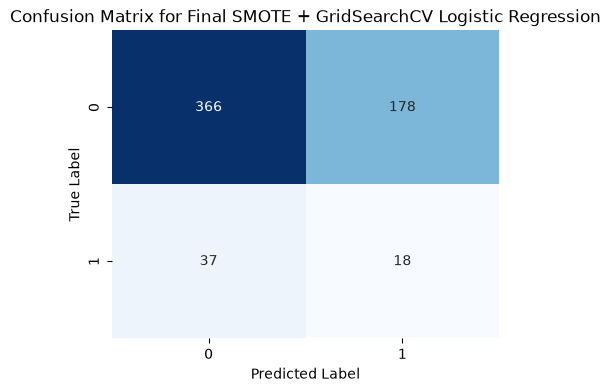

In [2001]:
# Compare SMOTE + GridSearchCV-selected models on the 25% test split.
final_split_results = smote_gridsearch_results_df.loc[
    smote_gridsearch_results_df["Test Split"] == "25%"
].copy()
best_final_row = final_split_results.sort_values(
    ["Risk F1-score", "Risk Recall", "Test Accuracy"], ascending=False
).iloc[0]
best_final_model_name = best_final_row["Model"]
best_final_model = smote_gridsearch_models[("25%", best_final_model_name)]
best_final_prediction = smote_gridsearch_predictions[("25%", best_final_model_name)]

print("Selected final model:", best_final_model_name)
print("Best parameters:", best_final_row["Best Parameters"])
print("GridSearchCV five-fold Recall:", best_final_row["GridSearch CV Recall"])
print("Selection order: risk-class F1, then Recall, then Accuracy as a tie-breaker")
print("Held-out test accuracy:", best_final_row["Test Accuracy"])
print("Precision for Depression_Risk = 1:", best_final_row["Risk Precision"])
print("Recall for Depression_Risk = 1:", best_final_row["Risk Recall"])
print("F1-score for Depression_Risk = 1:", best_final_row["Risk F1-score"])

# Display the confusion matrix for the selected SMOTE + GridSearchCV model.
final_confusion_matrix = confusion_matrix(y_test_25, best_final_prediction)
plt.figure(figsize=(5, 4))
sns.heatmap(final_confusion_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix for Final SMOTE + GridSearchCV " + best_final_model_name)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

#### Interpretation of the Final Confusion Matrix

For the selected Logistic Regression model on the 25% test set, the matrix is `[[366, 178], [37, 18]]`. It correctly identifies 18 of the 55 participants meeting the PHQ-9 risk cutoff, while missing 37. It also flags 178 participants who are below the cutoff as at risk. This matches the Recall of 32.7% and Precision of 9.2%: the model catches some more risk cases than the original model, but most positive predictions do not match the project target.

## Step 11: Interpretation and Conclusion

The following outputs answer the four research questions using the executed results. Feature importance is interpreted as model-based predictive contribution. SMOTE was applied only to training splits; held-out test data were not resampled. GridSearchCV selected parameters using five-fold Recall for the risk class.

In [2002]:
# Summarize the findings for RQ1-RQ4 from the executed analysis.
print("RQ1: Candidate factors ranked by SMOTE + GridSearchCV Random Forest feature importance:")
print(feature_importance)
print("Categorical predictors include sex, race/ethnicity, and the selected MCQ condition reports.")
print("Importance indicates predictive contribution in this fitted model; it is not evidence of causation.")

print("\nRQ2: Risk-class performance on the 25% held-out test set:")
print(tuning_results_df.loc[tuning_results_df["Test Split"] == "25%", ["Training Approach", "Model", "Test Accuracy", "Risk Precision", "Risk Recall", "Risk F1-score"]].to_string(index=False))
print("\nSelected final SMOTE + GridSearchCV model:", best_final_model_name)
print("Best parameters:", best_final_row["Best Parameters"])

print("\nRQ3: Compare risk-class Recall and F1 across test splits:")
print(tuning_results_df[["Test Split", "Training Approach", "Model", "Risk Recall", "Risk F1-score"]].to_string(index=False))

print("\nRQ4: SMOTE + GridSearchCV model comparison on the 25% held-out test set:")
print(final_split_results[["Model", "Best Parameters", "Test Accuracy", "Risk Precision", "Risk Recall", "Risk F1-score"]].to_string(index=False))
if final_split_results["Risk F1-score"].max() == 0:
    print("Neither SMOTE + GridSearchCV model detected the risk class on the 25% test set.")
else:
    print("Selected by the highest risk-class F1-score, with Recall and Accuracy as tie-breakers.")
print("Method limitation: standard SMOTE may create intermediate values for label-encoded categorical predictors.")

RQ1: Candidate factors ranked by SMOTE + GridSearchCV Random Forest feature importance:
INDFMPIR    0.209918
SLD012      0.136713
SLD013      0.131264
BMXBMI      0.105532
RIDAGEYR    0.099176
PAD680      0.089047
RIDRETH3    0.038802
MCQ220      0.033654
RIAGENDR    0.027411
MCQ160A     0.018436
MCQ160C     0.015962
MCQ550      0.015948
MCQ160M     0.014900
MCQ010      0.013434
MCQ160E     0.010527
MCQ160P     0.010130
MCQ160L     0.009166
MCQ160B     0.007847
MCQ160F     0.007579
MCQ160D     0.004554
dtype: float64
Categorical predictors include sex, race/ethnicity, and the selected MCQ condition reports.
Importance indicates predictive contribution in this fitted model; it is not evidence of causation.

RQ2: Risk-class performance on the 25% held-out test set:
     Training Approach               Model  Test Accuracy  Risk Precision  Risk Recall  Risk F1-score
Original training data Logistic Regression       0.898164        0.000000     0.000000       0.000000
Original training data

### Research Question Answers

Use the executed Step 10 results immediately above to answer RQ1–RQ4. The feature-importance output answers RQ1; the test metrics answer RQ2; the three test-split comparison answers RQ3; and the final 25% test-set comparison answers RQ4. Report the observed values from those outputs rather than assuming that resampling improved performance.

Categorical predictors were encoded with LabelEncoder, following the instructor's comparison-model materials. Standard SMOTE can interpolate their numeric codes, so this limitation should be considered when interpreting the resampled model results.